In [21]:
import pandas as pd
import numpy as np
from scipy import stats
import ast

from sklearn import metrics
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import roc_curve, roc_auc_score


import matplotlib.pyplot as plt


In [24]:
def classification_metrics(target, pred):
    tn, fp, fn, tp = metrics.confusion_matrix(target, pred).ravel()
    acc = (tp + tn) / (tn + fp + fn + tp)
    sen = tp / (tp + fn)
    spc = tn / (tn + fp)
    prc = tp / (tp + fp)
    mcc = ((tp * tn) - (fp * fn)) / ((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn) + .00000001) ** 0.5
    return acc.item(), sen.item(), spc.item(), prc.item(), mcc.item()

# acc, sen, spc, prc, mcc = classification_metrics(y_test, y_hat)

In [30]:
df_dock_1 = pd.read_csv("data/GlideDocking_20250616_PAH_0-20000_hitlist.csv", low_memory=False)
df_dock_2 = pd.read_csv("data/GlideDocking_20250616_PAH_20000-40000_hitlist.csv", low_memory=False)
df_dock = pd.concat([df_dock_1.iloc[1:], df_dock_2.iloc[1:]], ignore_index=True)
# df_dock = pd.concat([df_dock_1, df_dock_2], ignore_index=True)

df_dock = df_dock[['Title', 'Energy-1', 'docking score', 'glide emodel', 'glide gscore']]
df_dock['ID'] = [i.split('_')[0] for i in df_dock['Title']]
df_dock = df_dock.groupby('ID').aggregate('min')
# df_dock['ID'] = df_dock.index
df_dock.head()

,Title,Energy-1,docking score,glide emodel,glide gscore
ID,,,,,
BH4,BH4,4881.010,-6.054,-47.570,-6.054
CSCS00000001360,CSCS00000001360_0,15.275,-4.923,-31.623,-4.923
CSCS00000002301,CSCS00000002301_0,19.412,-4.873,-29.669,-4.873
CSCS00000005658,CSCS00000005658_0,-4.573,-4.924,-28.408,-4.924
CSCS00000007163,CSCS00000007163_0,-1.632,-4.963,-31.181,-4.963


In [31]:
control_ligands = [i for i in df_dock.index if i.find('CSCS') == -1]
control_affinity = df_dock.loc[df_dock.index.isin(control_ligands), 'docking score'].tolist()
control_ligands, control_affinity

(['BH4', 'Phe', 'Phenylalanine', 'Sepiapterin', 'UCR102', 'UCR243'],
 [-6.054, -4.498, -4.498, -3.793, -6.435, -6.342])

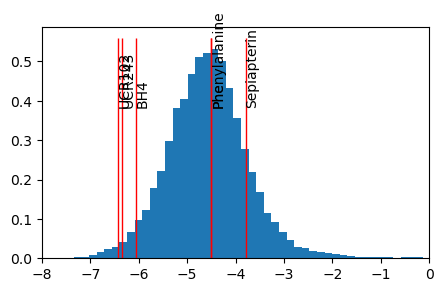

In [32]:
plt.figure(figsize=(5, 3))

plt.hist(df_dock['docking score'], 100, density=True);
y_max = plt.ylim()[1]
plt.vlines(control_affinity, ymin=0, ymax=y_max, color='red', linewidth = 1);
for lig, aff in zip(control_ligands, control_affinity):
    plt.text(x=aff, y=y_max*.7, s=lig, rotation = 90, size = 10)

plt.xlim([-8, 0]);

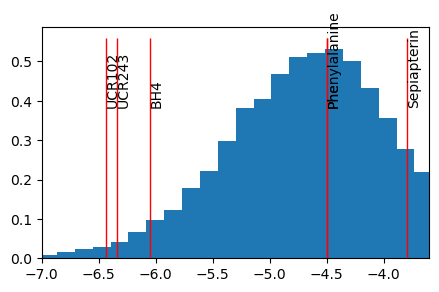

In [33]:
plt.figure(figsize=(5, 3))

plt.hist(df_dock['docking score'], 100, density=True);
y_max = plt.ylim()[1]
plt.vlines(control_affinity, ymin=0, ymax=y_max, color='red', linewidth = 1);
for lig, aff in zip(control_ligands, control_affinity):
    plt.text(x=aff, y=y_max*.7, s=lig, rotation = 90, size = 10)
plt.xlim([-7, -3.6]);

In [34]:
col_bind = 'Binding_validated_by_TSA'
protein = 'PAH-WT'
# col_bind = 'new'

df_expr = pd.read_csv("data/PO_norm_outlier_removed.csv")
# df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")

df_expr['bind_tsa'] = df_expr['bind_tsa'].apply(ast.literal_eval)
# df_expr[col_bind] = df_expr['bind_tsa'].map(conversion_dict)

df_expr = df_expr[['ID', 'Protein', col_bind]]
df_expr = df_expr.loc[~df_expr['ID'].isin(['BH4', 'UCR243', 'UCR102'])]
df_expr = df_expr.loc[df_expr['Protein'] == protein]
df_expr.head()

,ID,Protein,Binding_validated_by_TSA
2,CSCS00027898135,PAH-WT,no_evidence
3,CSCS00027264039,PAH-WT,no_evidence
4,CSCS00027379165,PAH-WT,weak_evidence
5,CSCS00028338246,PAH-WT,weak_evidence
6,CSCS00027378562,PAH-WT,no_evidence


In [35]:
df_merge = pd.merge(df_expr, df_dock, on = 'ID')
df_merge = df_merge.loc[df_merge[col_bind] != 'weak_evidence']
df_merge.head()

,ID,Protein,Binding_validated_by_TSA,Title,Energy-1,docking score,glide emodel,glide gscore
0,CSCS00027898135,PAH-WT,no_evidence,CSCS00027898135_0,140.132,-4.566,-36.432,-4.566
1,CSCS00027264039,PAH-WT,no_evidence,CSCS00027264039_0,64.258,-4.406,-54.362,-4.415
4,CSCS00027378562,PAH-WT,no_evidence,CSCS00027378562_0,-88.311,-4.246,-62.164,-4.704
5,CSCS00028232463,PAH-WT,no_evidence,CSCS00028232463_0,1.697,-4.703,-48.086,-4.703
6,CSCS00027378343,PAH-WT,no_evidence,CSCS00027378343_0,-85.551,-3.967,-42.673,-3.967


In [36]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'strong_evidence', 'glide gscore'].mean()

np.float64(-4.705520146520147)

In [37]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'no_evidence', 'glide gscore'].mean()

np.float64(-4.650586805555556)

In [38]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'weak_evidence', 'glide gscore'].mean()

nan

In [39]:
tab = df_merge.groupby(col_bind).size()
tab

Binding_validated_by_TSA
no_evidence        576
strong_evidence    273
dtype: int64

In [40]:
hit_ratio = (tab['strong_evidence'] / tab.sum()).item()
hit_ratio

0.3215547703180212

In [41]:
score = df_merge['docking score']
target = df_merge[col_bind] == 'strong_evidence'
total_pos = target.sum().item()
prc_chance = hit_ratio

In [42]:
percentage_set = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, hit_ratio*100]
percentage_set.sort()
df_result = pd.DataFrame(columns=['percentage', 'acc', 'sen', 'spc', 'prc', 'mcc', 'best_sen', 'sen_chance', 'best_prc', 'prc_chance'])

for percentage in percentage_set:
    # Obtain target and pred
    threshold = np.percentile(score, percentage)
    pred = score < threshold
    # Calculate best sen and prc
    top_k = pred.sum().item()
    sen_best = min(1, top_k / total_pos)
    prc_best = min(1, total_pos / top_k)
    sen_chance = percentage / 100
    # Calculate measures
    acc, sen, spc, prc, mcc = classification_metrics(target, pred)
    df_result.loc[len(df_result)] = [percentage, acc, sen, spc, prc, mcc, sen_best, sen_chance, prc_best, prc_chance]

df_result

,percentage,acc,sen,spc,prc,mcc,best_sen,sen_chance,best_prc,prc_chance
0,5.000000,0.665489,0.058608,0.953125,0.372093,0.024992,0.157509,0.050000,1.000000,0.321555
1,10.000000,0.644287,0.102564,0.901042,0.329412,0.005611,0.311355,0.100000,1.000000,0.321555
2,15.000000,0.633687,0.164835,0.855903,0.351562,0.027070,0.468864,0.150000,1.000000,0.321555
3,20.000000,0.610130,0.205128,0.802083,0.329412,0.008417,0.622711,0.200000,1.000000,0.321555
4,25.000000,0.579505,0.234432,0.743056,0.301887,-0.024293,0.776557,0.250000,1.000000,0.321555
5,30.000000,0.577150,0.307692,0.704861,0.330709,0.012805,0.930403,0.300000,1.000000,0.321555
6,32.155477,0.561837,0.318681,0.677083,0.318681,-0.004235,1.000000,0.321555,1.000000,0.321555
7,35.000000,0.552415,0.347985,0.649306,0.319865,-0.002653,1.000000,0.350000,0.919192,0.321555
8,40.000000,0.544170,0.413919,0.605903,0.332353,0.018895,1.000000,0.400000,0.802941,0.321555
9,45.000000,0.522968,0.457875,0.553819,0.327225,0.010980,1.000000,0.450000,0.714660,0.321555


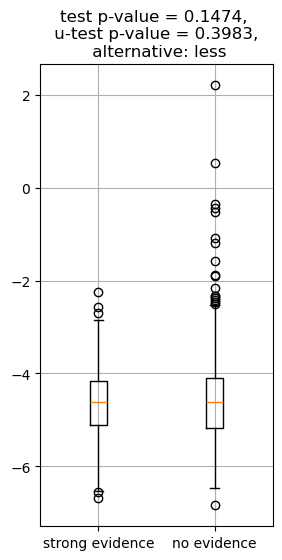

In [43]:
# Calculate p-value and boxplot
plt.figure(figsize=(3, 6))
pval_ttest = stats.ttest_ind(score[target], 
                        score[~target],
                        alternative='less',
                          ).pvalue.item()
pval_utest = stats.mannwhitneyu(score[target], 
                           score[~target],
                           alternative='less',
                          ).pvalue.item()
plt.boxplot([score[target], score[~target]]);
plt.grid()
plt.title(f'test p-value = {pval_ttest:.4f}, \n u-test p-value = {pval_utest:.4f}, \n alternative: less')
plt.xticks([1, 2], ['strong evidence', 'no evidence']);

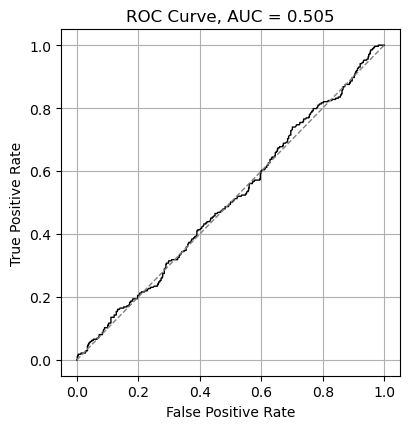

np.float64(0.5054754273504274)

In [44]:
auc_score = roc_auc_score(target, -score)
fpr, tpr, thresholds = roc_curve(target, -score)

plt.figure(figsize=(4, 4))

plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}', color = 'black', linewidth=1)
plt.plot([0, 1], [0, 1], '--', label='Random', color='gray', linewidth=1)
plt.grid(True)
plt.tight_layout()

plt.title(f'ROC Curve, AUC = {np.mean(auc_score):.3f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

auc_score